<div style="text-align: justify;">

# Smoking and Weight Gain — Exploratory Data Analysis

## Introduction

Understanding the consequences of quitting smoking is an important public health question. Although renouncing smoking is known to generate substantial health benefits, it is also often associated with short to medium term weight gain. This creates an interesting setting for causal analysis, since individuals who quit smoking may differ systematically from those who continue smoking in ways that also affect subsequent weight change. As a result, a simple comparison of average weight gain between quitters and non-quitters may reflect both the effect of smoking cessation and pre-existing differences between these groups.

This project uses data from the National Health and Nutrition Examination Survey Epidemiologic Follow-up Study (NHEFS) to investigate the relationship between smoking cessation and weight gain. The NHEFS data have been widely used in the causal inference literature as an observational setting in which treatment assignment is not randomized, making careful adjustment for confounding essential. In this context, the central causal question is whether quitting smoking leads to a change in body weight, and if so, by how much.

Before undertaking formal causal estimation, it is necessary to develop a clear understanding of the structure and quality of the data. For that reason, this first stage of the analysis focuses on Exploratory Data Analysis (EDA). The aim is to examine the composition of the dataset, identify the variables most relevant to the treatment and outcome of interest, assess missingness and coding issues, and describe baseline differences between individuals who quit smoking and those who did not. Particular attention is given to variables that may later act as confounders, since imbalance in these characteristics may bias naive comparisons.

The EDA is descriptive rather than causal. Its purpose is not to estimate the causal effect of quitting smoking, but rather to provide intuition about the data, detect potential data quality problems, and guide the specification of the subsequent causal models. The insights obtained at this stage will help motivate later methodological choices like propensity score modeling, PC-algorithm, g-computation.

</div>

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)

project_dir = os.path.dirname(os.getcwd())
data_dir = os.path.join(project_dir, "data")

df = pd.read_csv(os.path.join(data_dir, "nhefs_complete.csv"))
codebook = pd.read_csv(os.path.join(data_dir, "nhefs_codebook.csv"))

print(df.shape)
df.head()

(1566, 67)


,seqn,qsmk,death,yrdth,modth,dadth,sbp,dbp,sex,age,race,income,marital,school,education,ht,wt71,wt82,wt82_71,birthplace,smokeintensity,smkintensity82_71,smokeyrs,asthma,bronch,tb,hf,hbp,pepticulcer,colitis,hepatitis,chroniccough,hayfever,diabetes,polio,tumor,nervousbreak,alcoholpy,alcoholfreq,alcoholtype,alcoholhowmuch,pica,headache,otherpain,weakheart,allergies,nerves,lackpep,hbpmed,boweltrouble,wtloss,infection,active,exercise,birthcontrol,pregnancies,cholesterol,hightax82,price71,price82,tax71,tax82,price71_82,tax71_82,id,censored,older
0,233,0,0,NaN,NaN,NaN,175.0,96.0,0,42,1,19.0,2,7,1,174.1875,79.04,68.946040,-10.093960,47.0,30,-10,29,0,0,0,0,1,1,0,0,0,0,1,0,0,0,1,1,3,7.0,0,1,0,0,0,0,0,1,0,0,0,0,2,2,NaN,197.0,0.0,2.183594,1.739990,1.102295,0.461975,0.443787,0.640381,1,0,0
1,235,0,0,NaN,NaN,NaN,123.0,80.0,0,36,0,18.0,2,9,2,159.3750,58.63,61.234970,2.604970,42.0,20,-10,24,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,4.0,0,1,0,0,0,0,0,0,0,0,1,0,0,2,NaN,301.0,0.0,2.346680,1.797363,1.364990,0.571899,0.549316,0.792969,2,0,0
2,244,0,0,NaN,NaN,NaN,115.0,75.0,1,56,1,15.0,3,11,2,168.5000,56.81,66.224486,9.414486,51.0,20,-14,26,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,3,4,NaN,0,1,1,0,0,1,0,0,0,0,0,0,2,0,2.0,157.0,0.0,1.569580,1.513428,0.551270,0.230988,0.056198,0.320251,3,0,1
3,245,0,1,85.0,2.0,14.0,148.0,78.0,0,68,1,15.0,3,5,1,170.1875,59.42,64.410117,4.990117,37.0,3,4,53,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,2,3,4.0,0,0,1,1,0,0,0,0,0,0,0,1,2,2,NaN,174.0,0.0,1.506592,1.451904,0.524902,0.219971,0.054794,0.304993,4,0,1
4,252,0,0,NaN,NaN,NaN,118.0,77.0,0,40,0,18.0,2,11,2,181.8750,87.09,92.079251,4.989251,42.0,20,0,19,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,2,1,2.0,0,1,0,0,0,0,0,0,1,0,0,1,1,2,NaN,216.0,0.0,2.346680,1.797363,1.364990,0.571899,0.549316,0.792969,5,0,0


In [3]:
df_clean = df.copy()

## 1. Dataset overview

The dataset used in this analysis contains 1,566 observations and 67 variables. Several variables are particularly important for addressing the quitting of smoking and weight gain question. The main treatment variable is `qsmk`, which indicates whether an individual quit smoking between baseline and the 1982 follow-up (1 = yes, 0 = no). The primary outcome variables relate to body weight, including `wt71` (weight in 1971), `wt82` (weight in 1982), and `wt82_71` (the change in weight between 1971 and 1982). In addition, baseline smoking behavior is captured by variables such as `smokeintensity`, which measures the number of cigarettes smoked per day in 1971, and `smokeyrs`, which records the number of years the individual had smoked at baseline.


In [4]:
# Compare variable names in codebook vs dataset, and check for typos

code_vars = set(codebook["variable"].astype(str).str.strip())
data_vars = set(df.columns.astype(str).str.strip())

in_codebook_not_data = sorted(code_vars - data_vars)
in_data_not_codebook = sorted(data_vars - code_vars)

print("Variables in codebook but NOT in dataset:")
print(in_codebook_not_data)

print("\nVariables in dataset but NOT in codebook:")
print(in_data_not_codebook)

Variables in codebook but NOT in dataset:
['bithcontrol', 'smkintensity 82_71']

Variables in dataset but NOT in codebook:
['birthcontrol', 'censored', 'id', 'older', 'smkintensity82_71']


In [5]:
codebook["variable"] = codebook["variable"].replace({
    "bithcontrol": "birthcontrol",
    "smkintensity 82_71": "smkintensity82_71"
})

In [6]:
# Check whether there are still diferences. However: 'censored', 'id', 'older' are not present in codebook.

code_vars = set(codebook["variable"].astype(str).str.strip())
data_vars = set(df.columns.astype(str).str.strip())

in_codebook_not_data = sorted(code_vars - data_vars)
in_data_not_codebook = sorted(data_vars - code_vars)

print("Variables in codebook but NOT in dataset:")
print(in_codebook_not_data)

print("\nVariables in dataset but NOT in codebook:")
print(in_data_not_codebook)

Variables in codebook but NOT in dataset:
[]

Variables in dataset but NOT in codebook:
['censored', 'id', 'older']


In [7]:
codebook.sort_values('variable').head(20)

,variable,description
0,active,"IN YOUR USUAL DAY, HOW ACTIVE ARE YOU? IN 1971..."
1,age,AGE IN 1971
2,alcoholfreq,HOW OFTEN DO YOU DRINK? IN 1971 0: Almost ev...
3,alcoholhowmuch,"WHEN YOU DRINK, HOW MUCH DO YOU DRINK? IN 1971"
4,alcoholpy,"HAVE YOU HAD 1 DRINK PAST YEAR? IN 1971, 1:EV..."
5,alcoholtype,WHICH DO YOU MOST FREQUENTLY DRINK? IN 1971 1...
6,allergies,"USE ALLERGIES MEDICATION IN 1971, 1:EVER, 0:N..."
7,asthma,"DX ASTHMA IN 1971, 1:EVER, 0:NEVER"
8,birthcontrol,BIRTH CONTROL PILLS PAST 6 MONTHS? IN 1971 1:Y...
9,birthplace,CHECK STATE CODE - SECOND PAGE


## 2. Missingness: explicit missing values

Some variables contain explicit missing values recorded as `NaN`. In addition, the codebook shows that certain variables use special codes, such as `2`, to indicate missing information. A few variables also include categories labeled as Unknown, which may represent either missing information or a separate response category depending on the variable.

These issues are important because the way missing or non-standard values are handled can affect both the descriptive analysis and the later causal estimation. For this reason, missingness is examined not only through `NaN` values, but also through the coding rules reported in the codebook.

Examples from the codebook:

- `diabetes`: `2 = missing`
- `hbp`: `2 = missing`
- `hbpmed`: `2 = missing`
- `boweltrouble`: `2 = missing`
- `pica`: `2 = missing`
- `marital`: `8 = unknown`
- `alcoholfreq`: `5 = unknown`


In [8]:
nan_summary = pd.DataFrame({
    "variable": df_clean.columns,
    "dtype": df_clean.dtypes.astype(str).values,
    "n_missing": df_clean.isna().sum().values,
    "pct_missing": (df_clean.isna().mean() * 100).round(2).values
})

nan_summary = nan_summary[nan_summary["n_missing"] > 0].sort_values(
    ["n_missing", "pct_missing"], ascending=[False, False]
).reset_index(drop=True)

print(f"Number of variables with explicit NaN: {nan_summary.shape[0]}")
nan_summary

Number of variables with explicit NaN: 17


,variable,dtype,n_missing,pct_missing
0,yrdth,float64,1275,81.42
1,modth,float64,1271,81.16
2,dadth,float64,1271,81.16
3,pregnancies,float64,866,55.30
4,alcoholhowmuch,float64,397,25.35
5,birthplace,float64,90,5.75
6,hightax82,float64,90,5.75
7,price71,float64,90,5.75
8,price82,float64,90,5.75
9,tax71,float64,90,5.75


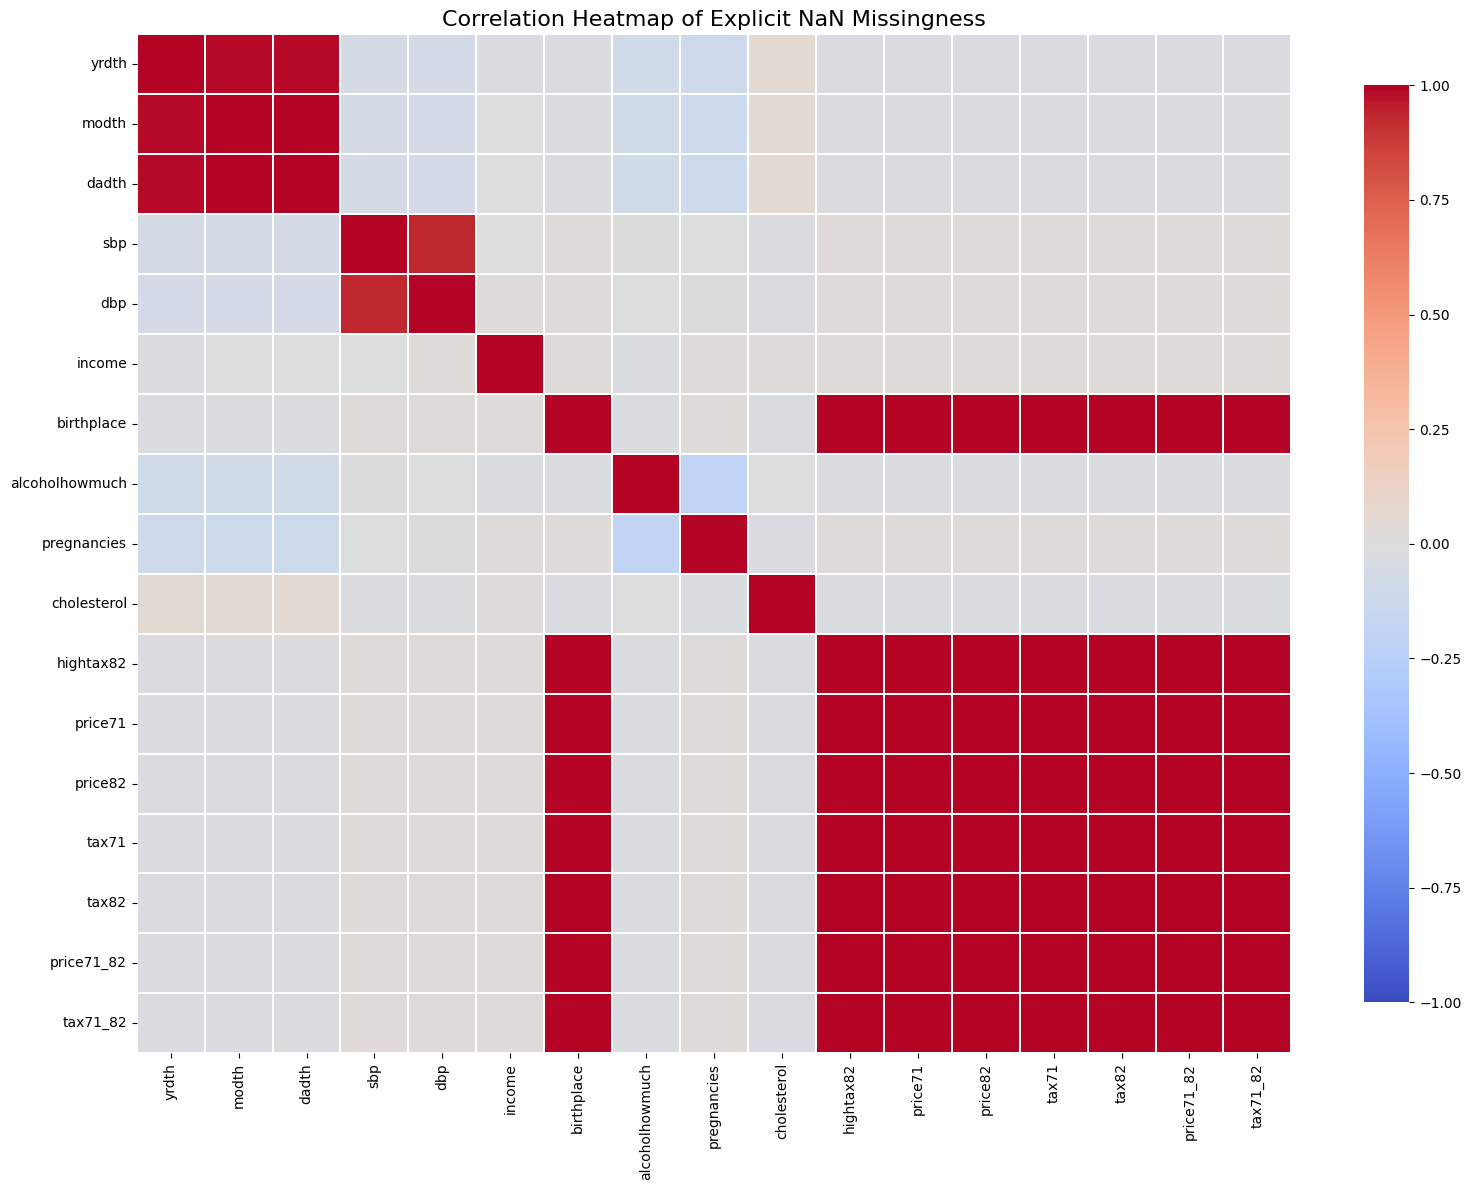

In [9]:
nan_vars = df_clean.columns[df_clean.isna().sum() > 0]
missing_matrix_nan = df_clean[nan_vars].isna().astype(int)
missing_corr_nan = missing_matrix_nan.corr()

plt.figure(figsize=(16, 12))
ax = sns.heatmap(
    missing_corr_nan,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.9}
)

ax.set_title("Correlation Heatmap of Explicit NaN Missingness", fontsize=16)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()

Identify variables with coded missing values:
+ Use the codebook to find variables where 2 = Missing
+ Manually add marital = 8: Unknown
+ Manually add alcoholfreq = 5: Unknown

In [10]:
# Variables where the codebook says 2 means missing
mask_2_missing = codebook["description"].str.contains(
    r"2\s*:\s*MISSING", case=False, na=False, regex=True
)

vars_2_missing = codebook.loc[mask_2_missing, "variable"].tolist()
vars_2_missing = [col for col in vars_2_missing if col in df_clean.columns]

# Add special unknown cases you want to treat as missing
special_missing_codes = {col: 2 for col in vars_2_missing}
special_missing_codes["marital"] = 8
special_missing_codes["alcoholfreq"] = 5

special_missing_codes

{'alcoholpy': 2,
 'birthcontrol': 2,
 'boweltrouble': 2,
 'diabetes': 2,
 'hbp': 2,
 'hbpmed': 2,
 'pica': 2,
 'marital': 8,
 'alcoholfreq': 5}

In [11]:
special_missing_summary = pd.DataFrame({
    "variable": list(special_missing_codes.keys()),
    "missing_code": list(special_missing_codes.values()),
    "n_special_code": [
        (df_clean[var] == code).sum()
        for var, code in special_missing_codes.items()
    ],
    "pct_special_code": [
        round((df_clean[var] == code).mean() * 100, 2)
        for var, code in special_missing_codes.items()
    ],
    "n_nan_before": [
        df_clean[var].isna().sum()
        for var in special_missing_codes.keys()
    ],
    "pct_nan_before": [
        round(df_clean[var].isna().mean() * 100, 2)
        for var in special_missing_codes.keys()
    ]
}).sort_values(["n_special_code", "n_nan_before"], ascending=[False, False]).reset_index(drop=True)

special_missing_summary

,variable,missing_code,n_special_code,pct_special_code,n_nan_before,pct_nan_before
0,birthcontrol,2,769,49.11,0,0.0
1,boweltrouble,2,769,49.11,0,0.0
2,diabetes,2,769,49.11,0,0.0
3,hbp,2,769,49.11,0,0.0
4,hbpmed,2,769,49.11,0,0.0
5,pica,2,769,49.11,0,0.0
6,alcoholpy,2,5,0.32,0,0.0
7,alcoholfreq,5,5,0.32,0,0.0
8,marital,8,1,0.06,0,0.0


Create dummy variables and recode original values to NaN, each new dummy is 1 if the variable is missing by our rule.
Missing means either:
+ already NaN
+ equal to the coded missing value

Then the original variable is recoded so the special code becomes NaN

In [12]:
for var, code in special_missing_codes.items():
    # Dummy = 1 if already NaN or if coded as missing/unknown
    df_clean[f"{var}_missing"] = (
        df_clean[var].isna() | (df_clean[var] == code)
    ).astype(int)
    
    # Recode special code to NaN in the original variable
    df_clean[var] = df_clean[var].replace(code, np.nan)

In [13]:
after_recode_summary = pd.DataFrame({
    "variable": list(special_missing_codes.keys()),
    "n_missing_after": [df_clean[var].isna().sum() for var in special_missing_codes.keys()],
    "pct_missing_after": [round(df_clean[var].isna().mean() * 100, 2) for var in special_missing_codes.keys()],
    "dummy_sum": [df_clean[f"{var}_missing"].sum() for var in special_missing_codes.keys()]
}).sort_values("n_missing_after", ascending=False).reset_index(drop=True)

after_recode_summary

,variable,n_missing_after,pct_missing_after,dummy_sum
0,birthcontrol,769,49.11,769
1,boweltrouble,769,49.11,769
2,diabetes,769,49.11,769
3,hbp,769,49.11,769
4,hbpmed,769,49.11,769
5,pica,769,49.11,769
6,alcoholpy,5,0.32,5
7,alcoholfreq,5,0.32,5
8,marital,1,0.06,1


In [14]:
missing_after = pd.DataFrame({
    "variable": df_clean.columns,
    "dtype": df_clean.dtypes.astype(str).values,
    "n_missing": df_clean.isna().sum().values,
    "pct_missing": (df_clean.isna().mean() * 100).round(2).values
})

missing_after = missing_after[missing_after["n_missing"] > 0].sort_values(
    ["n_missing", "pct_missing"], ascending=[False, False]
).reset_index(drop=True)

missing_after

,variable,dtype,n_missing,pct_missing
0,yrdth,float64,1275,81.42
1,modth,float64,1271,81.16
2,dadth,float64,1271,81.16
3,pregnancies,float64,866,55.30
4,hbp,float64,769,49.11
5,diabetes,float64,769,49.11
6,pica,float64,769,49.11
7,hbpmed,float64,769,49.11
8,boweltrouble,float64,769,49.11
9,birthcontrol,float64,769,49.11


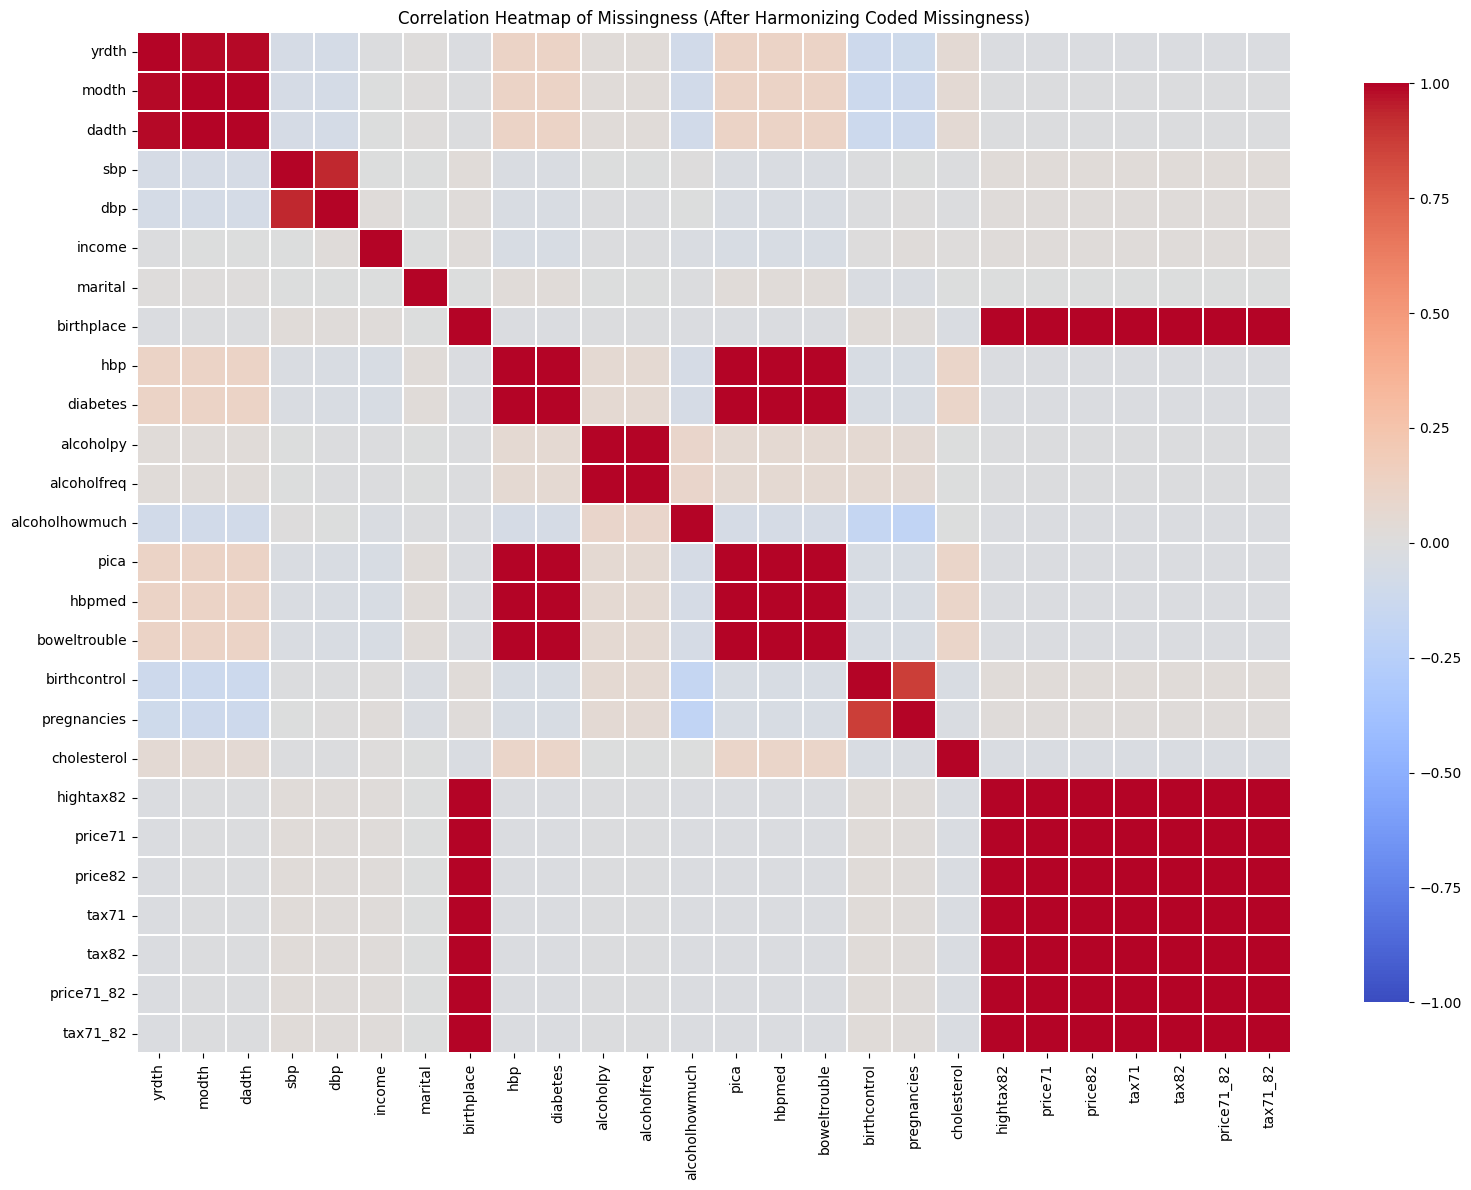

In [15]:
# Heatmap of missingness after harmonizing coded missing values to NaN

# variables with at least one NaN after harmonizing coded missingness
nan_vars_after = df_clean.columns[df_clean.isna().sum() > 0]

missing_matrix_after = df_clean[nan_vars_after].isna().astype(int)
missing_corr_after = missing_matrix_after.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    missing_corr_after,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.9}
)

plt.title("Correlation Heatmap of Missingness (After Harmonizing Coded Missingness)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Descriptive summary of the sample

This section gives a quick overall profile of the sample.


In [16]:
summary = pd.Series({
    'n': len(df_clean),
    'quit_rate_pct': 100 * df_clean['qsmk'].mean(),
    'mean_age': df_clean['age'].mean(),
    'female_pct': 100 * df_clean['sex'].mean(),           # codebook: 1 = female
    'black_or_other_pct': 100 * df_clean['race'].mean(),  # codebook: 1 = black or other
    'mean_weight_1971': df_clean['wt71'].mean(),
    'mean_weight_change': df_clean['wt82_71'].mean(),
    'mean_cigarettes_per_day': df_clean['smokeintensity'].mean(),
    'mean_years_smoking': df_clean['smokeyrs'].mean(),
    'death_pct': 100 * df_clean['death'].mean()
}).round(2)

summary

n                          1566.00
quit_rate_pct                25.73
mean_age                     43.66
female_pct                   51.34
black_or_other_pct           13.15
mean_weight_1971             70.83
mean_weight_change            2.64
mean_cigarettes_per_day      20.53
mean_years_smoking           24.59
death_pct                    18.58
dtype: float64

A few initial takeaways:

- Around **25.7%** of the sample quit smoking by 1982.
- The average participant is in the mid 40s.
- The average weight gain over the period is positive.
- There is substantial variation in smoking intensity and weight change.

Because this is a quitting smoking question, the most important EDA comparison is **quitters vs non-quitters**.


## 4. Quitters vs non-quitters at baseline

This comparison is central for causal inference.  
If people who quit already differ from people who continue smoking at baseline, then a simple comparison of average weight gain will mix:

- the effect of quitting, and
- pre-existing differences between the groups.

So this section could help in identifying plausible confounders.


In [17]:
quitters = df_clean[df_clean['qsmk'] == 1]
continuers = df_clean[df_clean['qsmk'] == 0]

def mean_sd(x):
    return f"{x.mean():.2f} ({x.std():.2f})"

def pct(x):
    return f"{100 * x.mean():.1f}%"

baseline_table = pd.DataFrame({
    'Variable': [
        'Age',
        'Female',
        'Black/other race',
        'Education (1-5)',
        'Cigarettes/day',
        'Years smoking',
        'Weight in 1971 (kg)',
        'Exercise (0-2)',
        'Daily activity (0-2)',
        'Alcohol frequency (coded scale)',
        'Weight loss medication'
    ],
    'Quit smoking (qsmk=1)': [
        mean_sd(quitters['age']),
        pct(quitters['sex']),
        pct(quitters['race']),
        mean_sd(quitters['education']),
        mean_sd(quitters['smokeintensity']),
        mean_sd(quitters['smokeyrs']),
        mean_sd(quitters['wt71']),
        mean_sd(quitters['exercise']),
        mean_sd(quitters['active']),
        mean_sd(quitters['alcoholfreq']),
        pct(quitters['wtloss'])
    ],
    'Continued smoking (qsmk=0)': [
        mean_sd(continuers['age']),
        pct(continuers['sex']),
        pct(continuers['race']),
        mean_sd(continuers['education']),
        mean_sd(continuers['smokeintensity']),
        mean_sd(continuers['smokeyrs']),
        mean_sd(continuers['wt71']),
        mean_sd(continuers['exercise']),
        mean_sd(continuers['active']),
        mean_sd(continuers['alcoholfreq']),
        pct(continuers['wtloss'])
    ]
})

baseline_table

,Variable,Quit smoking (qsmk=1),Continued smoking (qsmk=0)
0,Age,46.17 (12.21),42.79 (11.79)
1,Female,45.4%,53.4%
2,Black/other race,8.9%,14.6%
3,Education (1-5),2.79 (1.28),2.69 (1.15)
4,Cigarettes/day,18.60 (12.40),21.19 (11.48)
5,Years smoking,26.03 (12.74),24.09 (11.71)
6,Weight in 1971 (kg),72.35 (15.63),70.30 (15.18)
7,Exercise (0-2),1.25 (0.71),1.18 (0.74)
8,Daily activity (0-2),0.69 (0.66),0.63 (0.64)
9,Alcohol frequency (coded scale),1.95 (1.31),1.89 (1.29)


### Interpretation of the baseline comparison

The baseline comparison reveals several descriptive differences between individuals who quit smoking and those who did not. On average, quitters appear to be older, to have smoked for a greater number of years, and to have a higher baseline body weight. At the same time, they seem to report slightly lower smoking intensity at baseline, measured in cigarettes per day. Some differences are also visible in the distribution of sex and race across the two groups.

These patterns are important because they suggest that quitting smoking is not randomly assigned in the observed data. In other words, individuals who quit smoking differ systematically from those who continue smoking even before the outcome is measured. As a result, simple comparisons of weight change between the two groups are likely to reflect not only the effect of smoking cessation, but also pre existing differences in demographic and health related characteristics. This provides a clear motivation for the use of adjustment methods in the subsequent causal analysis.

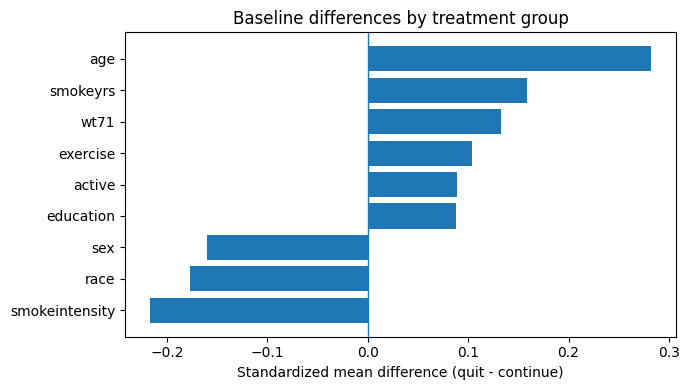

,variable,smd
0,age,0.281981
4,smokeintensity,-0.216675
2,race,-0.176918
1,sex,-0.160129
5,smokeyrs,0.158918
8,wt71,0.133216
6,exercise,0.103586
7,active,0.088714
3,education,0.087897


In [18]:
# Standardized mean differences for a small set of variables
selected = ['age', 'sex', 'race', 'education', 'smokeintensity', 'smokeyrs', 'exercise', 'active', 'wt71']

rows = []
for v in selected:
    x1 = quitters[v].astype(float)
    x0 = continuers[v].astype(float)
    smd = (x1.mean() - x0.mean()) / np.sqrt((x1.var(ddof=1) + x0.var(ddof=1)) / 2)
    rows.append({'variable': v, 'smd': smd})

smd_df = pd.DataFrame(rows).sort_values('smd')

plt.figure(figsize=(7,4))
plt.axvline(0, linewidth=1)
plt.barh(smd_df['variable'], smd_df['smd'])
plt.xlabel('Standardized mean difference (quit - continue)')
plt.ylabel('')
plt.title('Baseline differences by treatment group')
plt.tight_layout()
plt.show()

smd_df.sort_values('smd', key=np.abs, ascending=False)

## 5. Weight change: outcome exploration

Now we look at distribution of the outcome `wt82_71`, the change in weight from 1971 to 1982.
The distribution of weight change appears approximately bell-shaped, although it is not centered at zero. Instead, the mass of the distribution is shifted slightly to the right, indicating that weight gain was more common than weight loss over the period 1971–1982. A few observations in both tails suggest the presence of some extreme changes.

In [19]:
df_clean['wt82_71'].describe().round(2)

count    1566.00
mean        2.64
std         7.88
min       -41.28
25%        -1.48
50%         2.60
75%         6.69
max        48.54
Name: wt82_71, dtype: float64

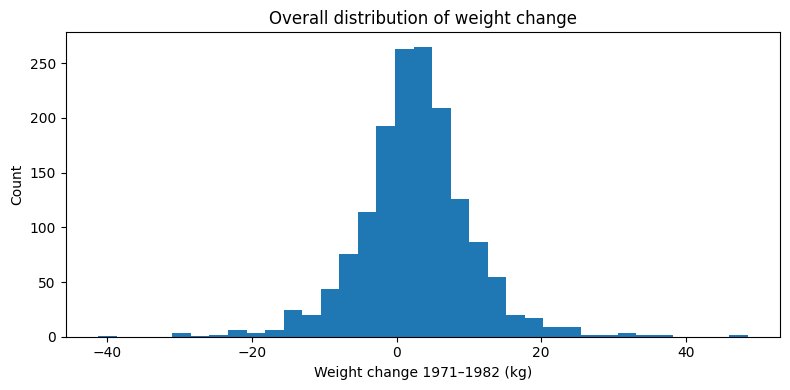

In [20]:
plt.figure(figsize=(8,4))
plt.hist(df_clean['wt82_71'], bins=35)
plt.xlabel('Weight change 1971–1982 (kg)')
plt.ylabel('Count')
plt.title('Overall distribution of weight change')
plt.tight_layout()
plt.show()

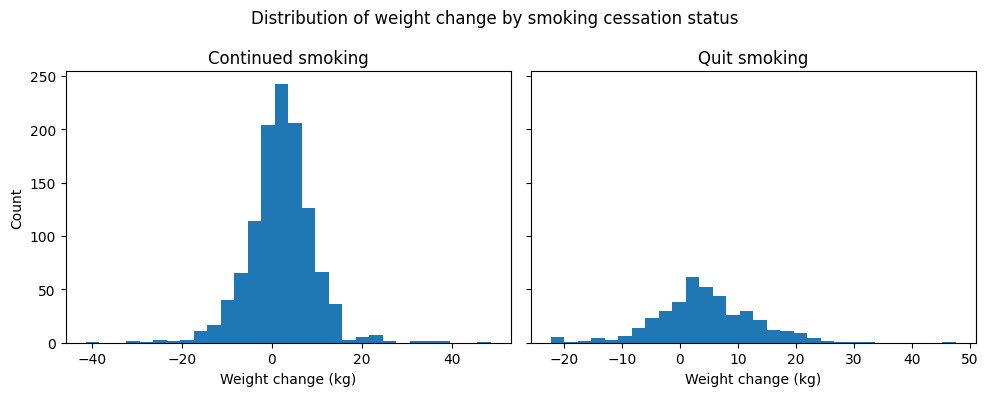

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)

for ax, q in zip(axes, [0, 1]):
    subset = df_clean.loc[df_clean['qsmk'] == q, 'wt82_71']
    ax.hist(subset, bins=30)
    ax.set_title('Continued smoking' if q == 0 else 'Quit smoking')
    ax.set_xlabel('Weight change (kg)')

axes[0].set_ylabel('Count')
fig.suptitle('Distribution of weight change by smoking cessation status')
fig.tight_layout()
plt.show()

Weight change appears to be distributed differently across the two groups. For those who continued smoking, the distribution is concentrated nearer to zero, whereas for those who quit smoking it is shifted toward positive values. This suggests, at the descriptive level, that quitters tended to gain more weight on average than continuing smokers.

In [22]:
weight_change_table = pd.DataFrame({
    'Group': ['Quit smoking', 'Continued smoking'],
    'N': [len(quitters), len(continuers)],
    'Mean weight change (kg)': [quitters['wt82_71'].mean(), continuers['wt82_71'].mean()],
    'Median weight change (kg)': [quitters['wt82_71'].median(), continuers['wt82_71'].median()],
    'SD weight change': [quitters['wt82_71'].std(), continuers['wt82_71'].std()],
    '5th percentile': [quitters['wt82_71'].quantile(0.05), continuers['wt82_71'].quantile(0.05)],
    '95th percentile': [quitters['wt82_71'].quantile(0.95), continuers['wt82_71'].quantile(0.95)]
}).round(2)

weight_change_table

,Group,N,Mean weight change (kg),Median weight change (kg),SD weight change,5th percentile,95th percentile
0,Quit smoking,403,4.53,3.97,8.75,-8.38,19.33
1,Continued smoking,1163,1.98,2.15,7.45,-10.09,12.80


## 6. Smoking behavior exploration

Baseline smoking intensity also looks somewhat different across the two groups. People who continued smoking seem to be a bit more concentrated at the higher levels of cigarette consumption, while those who later quit appear somewhat more common in the lower to middle part of the distribution. This suggests that the two groups may already differ in their smoking habits before quitting smoking is observed. This is important because baseline smoking behavior could later act as a confounder.

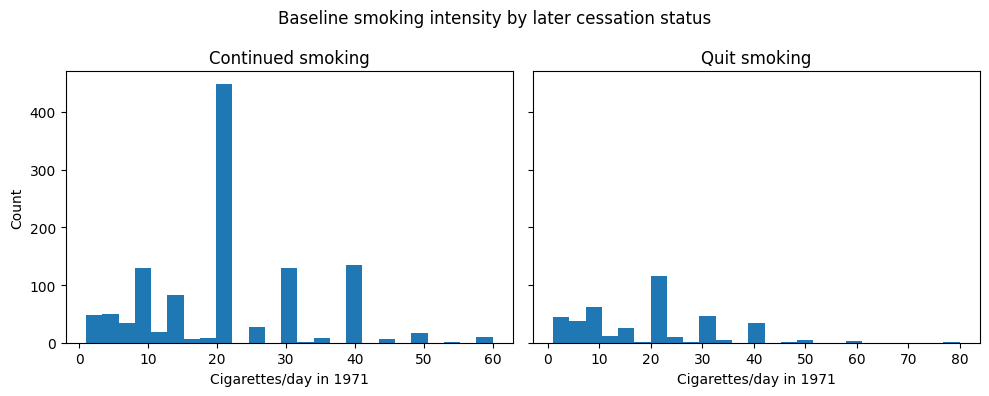

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)

for ax, q in zip(axes, [0, 1]):
    subset = df_clean.loc[df_clean['qsmk'] == q, 'smokeintensity']
    ax.hist(subset, bins=25)
    ax.set_title('Continued smoking' if q == 0 else 'Quit smoking')
    ax.set_xlabel('Cigarettes/day in 1971')

axes[0].set_ylabel('Count')
fig.suptitle('Baseline smoking intensity by later cessation status')
fig.tight_layout()
plt.show()

In [33]:
df_clean.groupby('qsmk')[['smokeintensity', 'smokeyrs']].agg(['mean', 'median', 'std']).round(2)

smokeintensity               smokeyrs              
               mean median    std     mean median    std
qsmk                                                    
0             21.19   20.0  11.48    24.09   23.0  11.71
1             18.60   20.0  12.40    26.03   26.0  12.74

## 7. EDA conclusions

Overall, the exploratory data analysis suggests that the NHEFS dataset is suitable for studying the relationship between quiting smoking and weight gain, but it also highlights several issues that are important for the later causal analysis. The data contain both explicit and coded missing values, which need to be handled carefully before modeling. Descriptively, individuals who quit smoking appear to gain more weight than those who continue smoking. At the same time, quitters and non-quitters differ at baseline in several characteristics, including age, smoking history, baseline weight, and smoking intensity. These baseline differences indicate that quitting smoking is not randomly assigned in the sample, so crude group comparisons cannot be interpreted as causal effects. Taken together, the EDA provides a useful foundation for the next stage of the project.